# 10 - Modelo de mayor techo: encoder Transformer + CTC

**Responsable:** María José Girón

Modelo de "mayor techo" según la selección de la revisión bibliográfica (Avance 2): la atención puede relacionar
cualquier par de cuadros de la secuencia, mientras que una red recurrente lo hace paso a paso. Usa la base común de
`06_preparacion_modelado` (mismos datos, mismo split por participante y mismo loop de entrenamiento), así que sus
resultados se comparan directamente con el CNN-BiGRU de `07_modelo_cnn_bigru`.

In [1]:
import sys
sys.path.append("..")

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from src import dataset, features, metrics, train, vocab
from src.models import transformer

sns.set_theme(style="whitegrid")
FIGS = "../reports/figures"
train.fijar_semilla(42)

## 1. Por qué este modelo

| Hallazgo | Decisión | Fuente |
|----------|----------|--------|
| Coarticulación: la forma de una letra depende de las vecinas | *Self-attention*: cada cuadro mira toda la secuencia en una sola capa, sin depender de un estado que se arrastra paso a paso | Vaswani et al. (2017) |
| Secuencias con mediana de 147 cuadros y cola hasta ~750 (recortadas a 384) | Conv1d con *stride* **antes** de la atención: el costo de la atención crece con T², así que acortar la secuencia la abarata | Gulati et al. (2020) |
| Las letras se distinguen por movimientos de pocos cuadros | La Conv1d (kernel 5) capta esos patrones locales, que la atención sola capta peor | Gulati et al. (2020) |
| El orden de los cuadros importa y la atención no lo conoce | Codificación posicional sinusoidal (sin parámetros extra) | Vaswani et al. (2017) |
| Solo 1,315 secuencias de entrenamiento | Encoder **pequeño** (3 capas, d = 128), *pre-norm* para un entrenamiento más estable, y dropout | Xiong et al. (2020) |
| La etiqueta es la frase completa, sin alineación cuadro-letra | Pérdida CTC | Graves et al. (2006) |

Las soluciones de los primeros lugares de la competencia de Kaggle usaron encoders tipo Transformer/Conformer sobre
*landmarks*; aquí se prueba una versión pequeña por el volumen de datos y el cómputo en CPU.

## 2. Arquitectura

```
x (B, T, 227) ─► Conv1d k=5, stride s ─► Conv1d k=5 ─► + posición ─► Encoder Transformer (N capas) ─► LayerNorm ─► Linear ─► log_softmax (B, T/s, 60)
```

- Cada Conv1d lleva BatchNorm, GELU y Dropout; después de cada una se pone en cero el relleno para que no se
  mezcle con los últimos cuadros reales.
- La atención recibe una máscara (`src_key_padding_mask`) para ignorar el relleno de las secuencias cortas.

In [2]:
loaders = dataset.crear_dataloaders(batch_size=32, max_frames=384)
x, x_len, y, y_len = next(iter(loaders["val"]))

modelo = transformer.construir()
modelo.eval()
log_probs, out_len = modelo(x, x_len)
print(modelo)
print()
print("entrada:", tuple(x.shape), "-> salida:", tuple(log_probs.shape))
print("largos de entrada:", x_len[:6].tolist())
print("largos de salida: ", out_len[:6].tolist())
print("parametros:", f"{train.n_parametros(modelo):,}")

TransformerCTC(
  (submuestreo): ModuleList(
    (0): Submuestreo(
      (conv): Conv1d(227, 128, kernel_size=(5,), stride=(2,), padding=(2,))
      (norm): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): GELU(approximate='none')
      (drop): Dropout(p=0.3, inplace=False)
    )
    (1): Submuestreo(
      (conv): Conv1d(128, 128, kernel_size=(5,), stride=(1,), padding=(2,))
      (norm): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): GELU(approximate='none')
      (drop): Dropout(p=0.3, inplace=False)
    )
  )
  (posicion): PosicionSinusoidal()
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        

Comprobación de la máscara: una secuencia procesada sola y la misma secuencia dentro de un batch con relleno deben dar
la misma salida.

In [3]:
with torch.no_grad():
    diferencias = [
        (modelo(x[i:i + 1, :x_len[i]], x_len[i:i + 1])[0][0] - log_probs[i, :out_len[i]]).abs().max().item()
        for i in range(8)
    ]
print(f"diferencia maxima: {max(diferencias):.2e}")

diferencia maxima: 1.19e-06


## 3. ¿Cuánto se puede reducir el tiempo?

CTC solo puede alinear si la salida tiene al menos tantos cuadros como letras tiene la frase (más uno por cada letra
repetida seguida). Además, la atención cuesta O(T²): reducir el tiempo la hace más barata.

In [4]:
cache = dataset.cargar_cache()
idx_train = dataset.indices_de(cache, "train")
largos = np.minimum(np.diff(cache["offsets"])[idx_train], 384)
frases = cache["phrase"][idx_train]
minimo_ctc = np.array([len(f) + sum(a == b for a, b in zip(f, f[1:])) for f in frases])

filas = []
for stride in (1, 2, 4):
    salida = (largos - 1) // stride + 1
    filas.append({"stride": stride, "cuadros_mediana": int(np.median(salida)),
                  "costo_atencion_relativo": round((384 / stride) ** 2 / 384 ** 2, 3),
                  "pct_secuencias_alineables": round(100 * (salida >= minimo_ctc).mean(), 1)})
pd.DataFrame(filas)

,stride,cuadros_mediana,costo_atencion_relativo,pct_secuencias_alineables
0,1,148,1.000,96.4
1,2,74,0.250,95.5
2,4,37,0.062,92.5


Con *stride* 2 la atención cuesta la cuarta parte y se pierde menos de un punto de secuencias alineables; con 4 cuesta
1/16, pero se pierden 3 puntos (92.5 % alineables). Se usa 2 como base y se prueba 4 en el ajuste.

## 4. Prueba rápida: ¿puede memorizar un batch?

Antes de entrenar en serio se comprueba que el modelo y la pérdida están bien conectados: sin dropout, con un solo
batch, la pérdida CTC debe bajar casi a cero y el CER del batch también.

In [5]:
train.fijar_semilla(42)
xb, xb_len, yb, yb_len = next(iter(loaders["train"]))
prueba = transformer.construir(dropout=0.0)
opt = torch.optim.AdamW(prueba.parameters(), lr=1e-3)
ctc = torch.nn.CTCLoss(blank=vocab.BLANK, zero_infinity=True)
perdidas = []
for paso in range(300):
    lp, ol = prueba(xb, xb_len)
    perdida = ctc(lp.transpose(0, 1), yb, ol, yb_len)
    opt.zero_grad()
    perdida.backward()
    opt.step()
    perdidas.append(perdida.item())

prueba.eval()
with torch.no_grad():
    lp, ol = prueba(xb, xb_len)
reales = [vocab.decode(f[:n].tolist()) for f, n in zip(yb, yb_len)]
print(f"perdida: {perdidas[0]:.2f} -> {perdidas[-1]:.4f} | CER del batch: {metrics.cer(reales, metrics.greedy_decode(lp, ol)):.3f}")

perdida: 13.40 -> 0.0051 | CER del batch: 0.070


## 5. Ajuste de hiperparámetros

Se parte de una configuración base y se cambia **un hiperparámetro a la vez**. Todas las corridas usan el mismo split,
la misma semilla, AdamW con *one-cycle* (que incluye un calentamiento del *learning rate*, importante en Transformers)
y *early stopping* por CER de validación, con el mismo presupuesto de 60 épocas que el CNN-BiGRU. **Test no se usa para
escoger**: solo se evalúa al final con el modelo elegido.

In [6]:
BASE = {"d_model": 128, "cabezas": 4, "capas": 3, "ff": 256, "stride": 2, "dropout": 0.3}
CONFIG_BASE = {"epochs": 60, "lr": 1e-3, "paciencia": 10}

# (cambio en la arquitectura, cambio en el entrenamiento)
VARIANTES = {
    "base": ({}, {}),
    "lr_3e-3": ({}, {"lr": 3e-3}),
    "stride_4": ({"stride": 4}, {}),
    "mas_capas": ({"capas": 6}, {}),
    "mas_ancho": ({"d_model": 192, "ff": 384}, {}),
    "dropout_0.1": ({"dropout": 0.1}, {}),
}

In [7]:
corridas, mejor = [], None
for nombre, (cambio_hp, cambio_cfg) in VARIANTES.items():
    hp = {**BASE, **cambio_hp}
    cfg = {**CONFIG_BASE, **cambio_cfg}
    train.fijar_semilla(42)
    modelo = transformer.construir(**hp)
    print(f"--- {nombre}: {cambio_hp or cambio_cfg or 'base'} ({train.n_parametros(modelo):,} parametros)")
    resultado = train.fit(modelo, loaders["train"], loaders["val"], cfg)
    corridas.append({"variante": nombre, "hiperparametros": hp, "config_entrenamiento": cfg,
                     "n_parametros": train.n_parametros(modelo), "mejor_cer_val": resultado["mejor_cer_val"],
                     "epocas": resultado["epocas"], "tiempo_s": resultado["tiempo_entrenamiento_s"],
                     "historial": resultado["historial"]})
    if mejor is None or resultado["mejor_cer_val"] < mejor[2]["mejor_cer_val"]:
        mejor = (nombre, modelo, resultado, hp)

train.METRICS_DIR.mkdir(parents=True, exist_ok=True)
with open(train.METRICS_DIR / "transformer_tuning.json", "w", encoding="utf-8") as f:
    json.dump(corridas, f, ensure_ascii=False, indent=2)

--- base: base (633,404 parametros)


epoca   1 | train 10.657 | val 4.954 | CER 1.000


epoca   2 | train 4.608 | val 4.085 | CER 1.000


epoca   3 | train 3.792 | val 3.766 | CER 1.000


epoca   4 | train 3.631 | val 3.620 | CER 1.000


...

epoca  56 | train 0.738 | val 2.863 | CER 0.589


epoca  57 | train 0.728 | val 2.887 | CER 0.586


epoca  58 | train 0.726 | val 2.884 | CER 0.590


epoca  59 | train 0.728 | val 2.880 | CER 0.597


epoca  60 | train 0.724 | val 2.871 | CER 0.584


In [8]:
tabla_tuning = pd.DataFrame(corridas)[["variante", "n_parametros", "mejor_cer_val", "epocas", "tiempo_s"]]
tabla_tuning["tiempo_min"] = (tabla_tuning.pop("tiempo_s") / 60).round(1)
tabla_tuning.sort_values("mejor_cer_val").round(3)

,variante,n_parametros,mejor_cer_val,epocas,tiempo_min
5,dropout_0.1,633404,0.584,60,17.8
2,stride_4,633404,0.588,60,7.5
4,mas_ancho,1306428,0.626,60,19.6
1,lr_3e-3,633404,0.640,60,19.2
3,mas_capas,1030844,0.654,60,36.0
0,base,633404,0.680,60,19.8


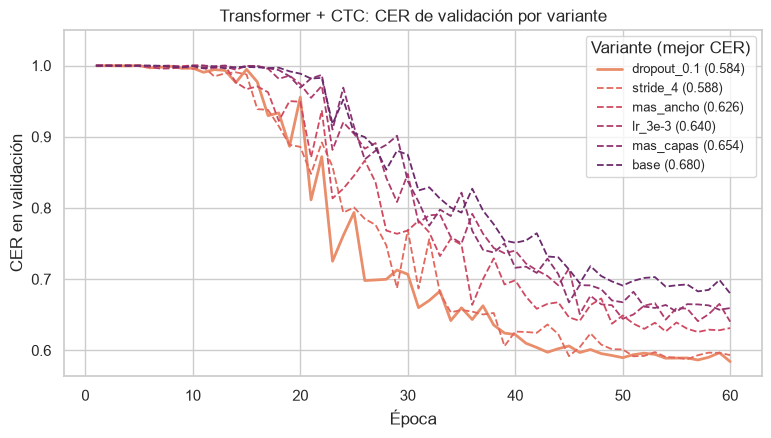

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
paleta = sns.color_palette("flare", len(corridas))
for color, c in zip(paleta, sorted(corridas, key=lambda c: c["mejor_cer_val"])):
    estilo = "-" if c["variante"] == mejor[0] else "--"
    ax.plot(range(1, len(c["historial"]["val_cer"]) + 1), c["historial"]["val_cer"], estilo,
            color=color, lw=2 if estilo == "-" else 1.3, label=f"{c['variante']} ({c['mejor_cer_val']:.3f})")
ax.set_xlabel("Época")
ax.set_ylabel("CER en validación")
ax.set_title("Transformer + CTC: CER de validación por variante")
ax.set_ylim(top=1.05)
ax.legend(title="Variante (mejor CER)", fontsize=9)
fig.savefig(f"{FIGS}/10_transformer_tuning.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura del ajuste:**

- **El cuello de botella es la velocidad de aprendizaje, no la capacidad.** Con 60 épocas, la base (0.680) todavía
  no había convergido: todo lo que acelera el aprendizaje ayudó (*learning rate* de 0.003 → 0.640; *dropout* de 0.1 →
  **0.584**), mientras que agregar capacidad ayudó poco (más ancho → 0.626) o casi nada (6 capas → 0.654, con casi el
  doble de tiempo). Con solo 1,315 secuencias, un Transformer más grande no tiene datos suficientes para aprovecharse.
- **Reducir más el tiempo casi no cuesta precisión:** con *stride* 4 se llegó a 0.588, prácticamente igual que la mejor
  variante, en **7.5 minutos** en vez de 18-20, porque la atención trabaja sobre la cuarta parte de posiciones
  (costo 1/16). Es el mismo resultado que obtuvo el CNN-BiGRU con *stride* 4.
- Ninguna variante activó el *early stopping*; todas seguían mejorando poco a poco en la época 60.

Se elige **`dropout_0.1`** por tener el menor CER de validación. Combinar *dropout* 0.1 con *stride* 4 y
*learning rate* 0.003 no se probó y es el siguiente paso natural.

## 6. Modelo final y evaluación en test

Se guarda la mejor variante con `train.guardar_resultados`, que la evalúa en validación y en test y escribe
`models/transformer.pt` y `reports/metrics/transformer.json` (formato común que leen la app y la comparación).

In [10]:
nombre_mejor, modelo_final, resultado_final, hp_final = mejor
print("Variante elegida:", nombre_mejor, hp_final)
reporte = train.guardar_resultados("transformer", modelo_final, hp_final, resultado_final, loaders)
pd.Series({k: reporte[k] for k in ["cer_val", "cer_test", "score_kaggle_test", "n_parametros",
                                   "epocas", "tiempo_entrenamiento_s", "ms_por_secuencia"]}).round(3)

Variante elegida: dropout_0.1 {'d_model': 128, 'cabezas': 4, 'capas': 3, 'ff': 256, 'stride': 2, 'dropout': 0.1}


transformer: CER val 0.584 | CER test 0.499 | 1.8 ms/secuencia


cer_val                        0.584
cer_test                       0.499
score_kaggle_test              0.501
n_parametros              633404.000
epocas                        60.000
tiempo_entrenamiento_s      1068.869
ms_por_secuencia               1.768
dtype: float64

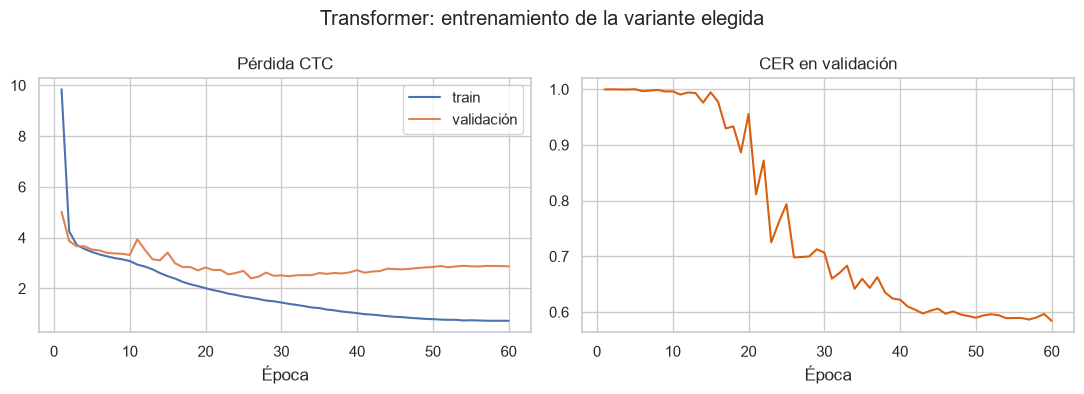

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
h = reporte["historial"]
epocas = range(1, len(h["train_loss"]) + 1)
axes[0].plot(epocas, h["train_loss"], label="train")
axes[0].plot(epocas, h["val_loss"], label="validación")
axes[0].set_title("Pérdida CTC")
axes[0].set_xlabel("Época")
axes[0].legend()
axes[1].plot(epocas, h["val_cer"], color="#d95f0e")
axes[1].set_title("CER en validación")
axes[1].set_xlabel("Época")
fig.suptitle("Transformer: entrenamiento de la variante elegida")
fig.tight_layout()
fig.savefig(f"{FIGS}/10_transformer_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Comparación con el modelo principal (CNN-BiGRU)

Ambos modelos comparten datos, split, preprocesamiento y loop de entrenamiento, así que la comparación es directa.
Desde aquí el notebook lee `reports/metrics/*.json` y se puede volver a correr sin reentrenar.

In [12]:
reporte = json.loads((train.METRICS_DIR / "transformer.json").read_text(encoding="utf-8"))
reporte_cnn = json.loads((train.METRICS_DIR / "cnn_bigru.json").read_text(encoding="utf-8"))

columnas = ["cer_val", "cer_test", "n_parametros", "epocas", "tiempo_entrenamiento_s", "ms_por_secuencia"]
comparacion = pd.DataFrame({"CNN-BiGRU": {k: reporte_cnn[k] for k in columnas},
                            "Transformer": {k: reporte[k] for k in columnas}}).T
comparacion["tiempo_min"] = (comparacion.pop("tiempo_entrenamiento_s") / 60)
comparacion.round(3)

,cer_val,cer_test,n_parametros,epocas,ms_por_secuencia,tiempo_min
CNN-BiGRU,0.552,0.490,1696060.0,60.0,5.340,47.664
Transformer,0.584,0.499,633404.0,60.0,1.768,17.814


CER por secuencia de test en ambos modelos (mismas 268 secuencias): ¿el Transformer gana o pierde de forma
consistente, o depende de la secuencia?

Transformer mejor en 103 secuencias, peor en 105, empate en 60
Wilcoxon (pareado): p = 0.2077


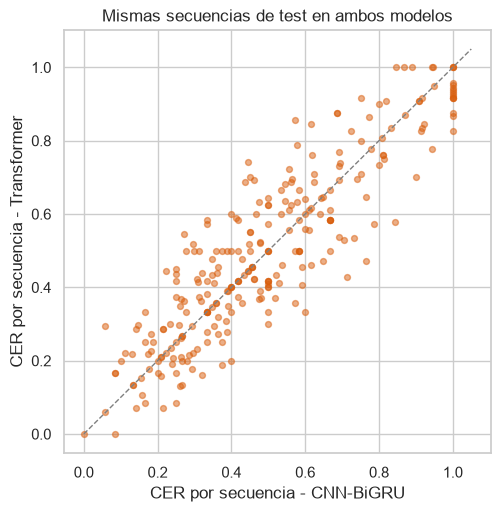

In [13]:
from scipy import stats

cer_seq = pd.DataFrame({
    "cnn_bigru": [metrics.cer([p["real"]], [p["predicha"]]) for p in reporte_cnn["predicciones_test"]],
    "transformer": [metrics.cer([p["real"]], [p["predicha"]]) for p in reporte["predicciones_test"]],
})
dif = cer_seq["transformer"] - cer_seq["cnn_bigru"]
print(f"Transformer mejor en {(dif < 0).sum()} secuencias, peor en {(dif > 0).sum()}, empate en {(dif == 0).sum()}")
print(f"Wilcoxon (pareado): p = {stats.wilcoxon(cer_seq['transformer'], cer_seq['cnn_bigru']).pvalue:.4f}")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(cer_seq["cnn_bigru"], cer_seq["transformer"], alpha=0.5, s=18, color="#d95f0e")
lim = max(cer_seq.max()) * 1.05
ax.plot([0, lim], [0, lim], "--", color="gray", lw=1)
ax.set_xlabel("CER por secuencia - CNN-BiGRU")
ax.set_ylabel("CER por secuencia - Transformer")
ax.set_title("Mismas secuencias de test en ambos modelos")
fig.savefig(f"{FIGS}/10_transformer_vs_cnn_bigru.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Qué letras falla

Se cruza la tasa de error por carácter en test con cuántas veces aparece cada carácter en entrenamiento, igual que en
el modelo principal.

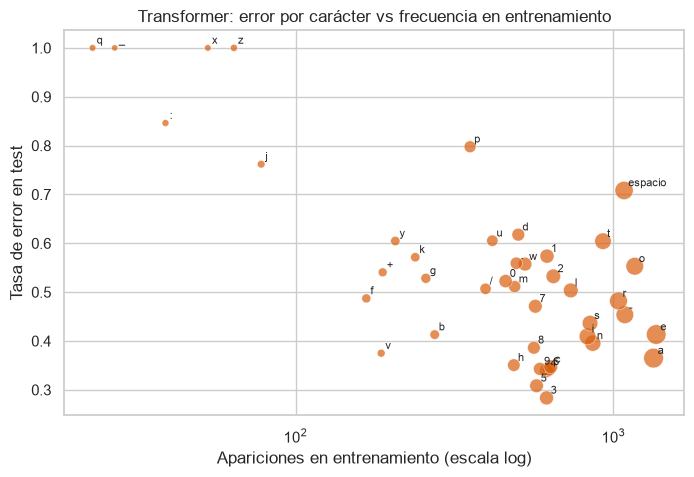

Correlación de Spearman: -0.496


In [14]:
conteo_train = pd.Series(list("".join(frases))).value_counts()
por_caracter = pd.DataFrame(reporte["cer_por_caracter"]["por_caracter"]).T
por_caracter["apariciones_train"] = por_caracter.index.map(conteo_train).fillna(0).astype(int)
por_caracter = por_caracter[por_caracter["total"] >= 5].sort_values("tasa")

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=por_caracter, x="apariciones_train", y="tasa", size="total", sizes=(20, 200),
                color="#d95f0e", alpha=0.7, legend=False, ax=ax)
for c, fila in por_caracter.iterrows():
    ax.annotate("espacio" if c == " " else c, (fila["apariciones_train"], fila["tasa"]), fontsize=8,
                xytext=(3, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("Apariciones en entrenamiento (escala log)")
ax.set_ylabel("Tasa de error en test")
ax.set_title("Transformer: error por carácter vs frecuencia en entrenamiento")
fig.savefig(f"{FIGS}/10_transformer_error_por_caracter.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlación de Spearman:", round(por_caracter[["apariciones_train", "tasa"]].corr("spearman").iloc[0, 1], 3))

In [15]:
pd.Series(reporte["cer_por_caracter"]["confusiones"]).head(15).rename("veces").to_frame()

,veces
-><borrado>,128
t-><borrado>,92
e-><borrado>,90
o-><borrado>,78
r-><borrado>,76
a-><borrado>,68
--><borrado>,65
i-><borrado>,58
l-><borrado>,57
s-><borrado>,54


In [16]:
def tipos_de_error(predicciones):
    tipos = {"borrado": 0, "sustitucion": 0, "insercion": 0}
    for p in predicciones:
        for c_ref, c_hyp in metrics.alinear(p["real"], p["predicha"]):
            if not c_hyp:
                tipos["borrado"] += 1
            elif not c_ref:
                tipos["insercion"] += 1
            elif c_ref != c_hyp:
                tipos["sustitucion"] += 1
    return pd.Series(tipos)

tabla_tipos = pd.DataFrame({"transformer": tipos_de_error(reporte["predicciones_test"]),
                            "cnn_bigru": tipos_de_error(reporte_cnn["predicciones_test"])})
for col in ["transformer", "cnn_bigru"]:
    tabla_tipos[f"pct_{col}"] = (100 * tabla_tipos[col] / tabla_tipos[col].sum()).round(1)
vacias = sum(p["predicha"] == "" for p in reporte["predicciones_test"])
print(f"Predicciones vacias del Transformer: {vacias} de {len(reporte['predicciones_test'])}")
tabla_tipos

Predicciones vacias del Transformer: 2 de 268


,transformer,cnn_bigru,pct_transformer,pct_cnn_bigru
borrado,1601,1754,68.3,76.2
sustitucion,664,496,28.3,21.6
insercion,80,51,3.4,2.2


In [17]:
ejemplos = pd.DataFrame(reporte["predicciones_test"])
ejemplos["cer"] = [metrics.cer([r], [p]) for r, p in zip(ejemplos["real"], ejemplos["predicha"])]
pd.concat([ejemplos.nsmallest(5, "cer"), ejemplos.nlargest(5, "cer")])[["real", "predicha", "cer"]].round(3)

,real,predicha,cer
77,848-496-8336,848-496-8336,0.000
186,+61-6543-4086-36-79,+61-6543-4086-36-79,0.000
155,+48-0295-3409-066,+48-0295-3409-06,0.059
130,+45-040-39-831,+045-040-39-831,0.071
191,+383-0157-9304,+3832-0157-9304,0.071
19,+597-607-0250-9522,28 wo lriwovava,1.000
112,3810 portico estate,,1.000
121,+291-04-9141-70-0281-58,3,1.000
142,duisburg-huckingen,,1.000
169,www.irineka.eu,3,1.000


## 9. ¿Influyen los faltantes y la velocidad de deletreo?

Mismo análisis que en el modelo principal: CER de cada secuencia de test contra su cobertura de mano y los cuadros
disponibles por carácter.

In [18]:
pos = {sid: i for i, sid in enumerate(cache["sequence_id"])}
filas = []
for p in reporte["predicciones_test"]:
    j = pos[p["sequence_id"]]
    mascara = cache["X"][cache["offsets"][j]:cache["offsets"][j + 1], -2:].astype(np.float32)
    filas.append({
        "cobertura_mano": features.cobertura_mano(mascara),
        "cuadros_por_caracter": len(mascara) / max(len(p["real"]), 1),
        "cer": metrics.cer([p["real"]], [p["predicha"]]),
    })
por_secuencia = pd.DataFrame(filas)

print("Spearman con el CER:")
print(por_secuencia.corr("spearman")["cer"].drop("cer").round(3).to_string())
por_secuencia["grupo_velocidad"] = pd.qcut(por_secuencia["cuadros_por_caracter"], 4,
                                           labels=["muy rapido", "rapido", "lento", "muy lento"])
por_secuencia.groupby("grupo_velocidad", observed=True)["cer"].agg(["count", "mean"]).round(3)

Spearman con el CER:
cobertura_mano         -0.741
cuadros_por_caracter   -0.344


,count,mean
grupo_velocidad,,
muy rapido,67,0.644
rapido,67,0.513
lento,67,0.411
muy lento,67,0.443


## 10. Conclusiones del Transformer

- **Desempeño:** CER de **0.499 en test** (0.584 en validación): transcribe correctamente alrededor del 50 % de los
  caracteres de personas que no vio al entrenar. Queda prácticamente empatado con el CNN-BiGRU (0.490): sobre las
  mismas 268 secuencias, el Transformer gana en 103, pierde en 105 y empata en 60, y la diferencia **no es
  estadísticamente significativa** (Wilcoxon pareado, p = 0.21).
- **Costo:** logra ese resultado con **0.63 M de parámetros** (37 % de los del CNN-BiGRU), **18 minutos** de
  entrenamiento en CPU (contra 48) y **1.8 ms por secuencia** al predecir (contra 5.3). Por costo-beneficio es el
  modelo más eficiente de los dos.
- **Sobreajuste:** la pérdida de entrenamiento siguió bajando hasta 0.72 mientras la de validación subió desde la época
  ~30 (de 2.5 a 2.9); el CER de validación se estancó en ~0.59 desde la época 45. Con tan pocos datos, la atención
  memoriza el conjunto de entrenamiento; la aumentación de datos es la mejora más directa.
- **Mismo patrón de errores que el CNN-BiGRU, con matices:**
  - Domina el **borrado** de letras (68 %), aunque menos que en el CNN-BiGRU (76 %); a cambio sustituye más (28 % contra
    22 %): se atreve a emitir más caracteres, a veces equivocados.
  - Los **faltantes de mano** vuelven a ser el factor que más explica el error (Spearman −0.74).
  - El **desbalance de caracteres** se repite: q, x y z se fallan siempre (Spearman −0.50 entre frecuencia y error).
  - El deletreo **rápido** es más difícil (CER 0.644 en el cuartil más rápido contra 0.411-0.443 en los lentos).
  - Acierta mejor los **números de teléfono** (los dígitos y guiones siguen un patrón) que las palabras raras de URLs y
    direcciones.
- **¿Cumplió el papel de "mayor techo"?** En este volumen de datos, no superó al modelo principal, pero lo igualó con
  mucho menos costo. La literatura (soluciones de Kaggle) muestra que su ventaja aparece con muchos más datos; aquí
  el límite lo pone el tamaño del conjunto de entrenamiento, no la arquitectura.
- **Cómo mejorarlo:** aumentación (`src/augment.py`), más archivos de la competencia, combinar *dropout* 0.1 con
  *stride* 4 y *learning rate* 0.003, y más épocas con un *early stopping* que ya no dependa solo de 60 épocas.